# E1 — Chỉ số nào đánh giá khả năng dự đoán tốt nhất?

**Notebook học theo từng bước** của giai đoạn 3. Đọc cùng: [`../E1-chi-so-danh-gia.md`](../E1-chi-so-danh-gia.md) (báo cáo, viết sau) và [`../PHUONG-PHAP.md`](../PHUONG-PHAP.md) (khung 7 bước).

**Cách dùng trong VS Code**
1. Góc phải trên: **Select Kernel → Python Environments → `.venv`** (Python 3.11 của dự án).
2. Chạy từng ô bằng **Shift + Enter**, từ trên xuống. Kết quả đã chạy sẵn; chạy lại sẽ ra đúng như vậy.
3. Mỗi phần có bốn mục: **Đang làm gì** → **Đoán trước** (tự trả lời trước khi chạy) → ô code → **Đọc kết quả**.

| Bước nhỏ | Nội dung | Trạng thái |
| --- | --- | --- |
| **3.1** | Tính tay các chỉ số trên 5 giờ thật | Xong |
| **3.2** | Cách đoán ngây thơ làm mốc so sánh (MASE) | Xong |
| **3.3** | Chạy model thật của dự án, đối chiếu hệ thống | Xong |
| **3.4** | So các chỉ số trên 3 dataset | Xong |
| **3.5** | Quyết định và viết báo cáo | Xong |

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Tìm thư mục gốc dự án (nơi có data/real), dù notebook mở từ đâu.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "real").is_dir())
sys.path.insert(0, str(ROOT))
pd.set_option("display.precision", 1)
print("Thư mục dự án:", ROOT)

Thư mục dự án: D:\You Are Here\HK_VII\KLTN\Project\main_project


---
## Bước 3.1 — Tính tay các chỉ số trên 5 giờ thật

**Đang làm gì.** Trước khi train model nào, ta hiểu từng chỉ số "nghĩ" ra sao bằng cách tính tay trên **5 giờ** của dữ liệu thật I‑94 Minneapolis (thứ Tư 12/10/2016, lúc 3, 7, 12, 17 và 23 giờ).

"Dự đoán" ở đây **chưa phải model**: dùng cách đơn giản nhất — **lấy số xe cùng giờ của thứ Tư tuần trước**. Dùng cách này vì nó là số thật, không phải số tự đặt ra.

> **Đoán trước** (ghi ra giấy):
> 1. Giờ nào bị đoán sai **nhiều xe** nhất?
> 2. Giờ nào bị đoán sai **nhiều phần trăm** nhất? Có trùng câu 1 không?

In [2]:
i94 = pd.read_csv(
    ROOT / "data/real/i94-minneapolis/TrafficVolumeData_I94_Minneapolis_2012_2018.csv",
    parse_dates=["date_time"], keep_default_na=False,
).set_index("date_time")["traffic_volume"]

DAY = pd.Timestamp("2016-10-12")        # tự thử: đổi ngày khác rồi chạy lại
HOURS = [3, 7, 12, 17, 23]
times = [DAY + pd.Timedelta(hours=h) for h in HOURS]

y = i94.reindex(times).to_numpy(dtype=float)                                     # thực tế
y_hat = i94.reindex([t - pd.Timedelta(days=7) for t in times]).to_numpy(dtype=float)  # dự đoán = tuần trước
e = y - y_hat                                                                     # sai số

table = pd.DataFrame({
    "Giờ": HOURS,
    "Thực tế y": y,
    "Dự đoán ŷ": y_hat,
    "Sai số e = y − ŷ": e,
    "|e| (xe)": np.abs(e),
    "e²": (e ** 2).astype(int),
    "|e| / y (%)": np.abs(e) / y * 100,
})
table

,Giờ,Thực tế y,Dự đoán ŷ,Sai số e = y − ŷ,|e| (xe),e²,|e| / y (%)
0,3,270.0,316.0,-46.0,46.0,2116,17.0
1,7,5871.0,6046.0,-175.0,175.0,30625,3.0
2,12,4278.0,4581.0,-303.0,303.0,91809,7.1
3,17,5762.0,5687.0,75.0,75.0,5625,1.3
4,23,864.0,2110.0,-1246.0,1246.0,1552516,144.2


**Đọc kết quả.** Lúc 23 giờ bị sai nhiều nhất theo **cả hai** cách đo (1.246 xe, tức 144%). Nhưng thứ tự các giờ còn lại thì đảo: lúc 12 giờ sai 303 xe nhưng chỉ 7%, còn lúc 3 giờ sáng chỉ sai 46 xe mà đã 17%. **Cùng một bảng sai số, "giờ nào tệ" phụ thuộc vào cách đo.**

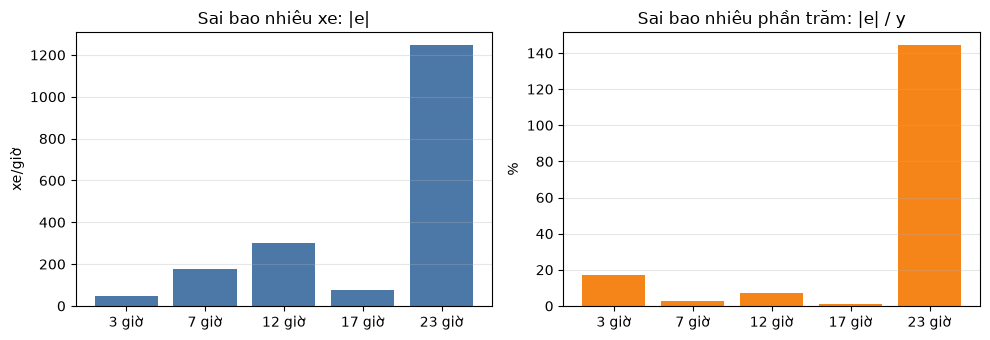

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
labels = [f"{h} giờ" for h in HOURS]
axes[0].bar(labels, np.abs(e), color="#4C78A8")
axes[0].set_title("Sai bao nhiêu xe: |e|")
axes[0].set_ylabel("xe/giờ")
axes[1].bar(labels, np.abs(e) / y * 100, color="#F58518")
axes[1].set_title("Sai bao nhiêu phần trăm: |e| / y")
axes[1].set_ylabel("%")
for ax in axes:
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Tính từng chỉ số

| Chỉ số | Công thức bằng lời |
| --- | --- |
| **MAE** | Trung bình của \|e\| — trung bình mỗi giờ sai bao nhiêu xe |
| **RMSE** | Căn bậc hai của trung bình e² — bình phương nên giờ sai lớn bị "phạt" nặng hơn |
| **MAPE** | Trung bình của \|e\| / y, nhân 100 — trung bình mỗi giờ sai bao nhiêu % |
| **sMAPE** | Trung bình của 2·\|e\| / (y + ŷ), nhân 100 — chia cho trung bình của thực tế và dự đoán |
| **WAPE** | Tổng \|e\| chia tổng y, nhân 100 — "sai bao nhiêu % tổng lưu lượng" |
| **R²** | 1 − (tổng e²) / (tổng (y − ȳ)²) — tốt hơn bao nhiêu so với việc đoán mọi giờ bằng trung bình ȳ |

MASE cần thêm dữ liệu quá khứ, để sang bước 3.2.

> **Đoán trước:** MAPE và WAPE đều là "phần trăm". Hai số có gần nhau không?

In [4]:
n = len(y)
MAE = np.mean(np.abs(e))
RMSE = np.sqrt(np.mean(e ** 2))
MAPE = np.mean(np.abs(e) / y) * 100
sMAPE = np.mean(2 * np.abs(e) / (np.abs(y) + np.abs(y_hat))) * 100
WAPE = np.sum(np.abs(e)) / np.sum(np.abs(y)) * 100
R2 = 1 - np.sum(e ** 2) / np.sum((y - y.mean()) ** 2)

join = lambda values: " + ".join(f"{v:,.0f}" for v in values)
print(f"MAE   = ({join(np.abs(e))}) / {n} = {MAE:,.1f} xe/giờ")
print(f"RMSE  = √(({join(e ** 2)}) / {n}) = {RMSE:,.1f} xe/giờ")
print(f"MAPE  = trung bình({', '.join(f'{v:.1f}%' for v in np.abs(e) / y * 100)}) = {MAPE:.1f}%")
print(f"sMAPE = trung bình({', '.join(f'{v:.1f}%' for v in 2 * np.abs(e) / (y + y_hat) * 100)}) = {sMAPE:.1f}%")
print(f"WAPE  = {np.sum(np.abs(e)):,.0f} / {np.sum(y):,.0f} = {WAPE:.1f}%")
print(f"R²    = 1 − {np.sum(e ** 2):,.0f} / {np.sum((y - y.mean()) ** 2):,.0f} = {R2:.3f}")

MAE   = (46 + 175 + 303 + 75 + 1,246) / 5 = 369.0 xe/giờ
RMSE  = √((2,116 + 30,625 + 91,809 + 5,625 + 1,552,516) / 5) = 580.1 xe/giờ
MAPE  = trung bình(17.0%, 3.0%, 7.1%, 1.3%, 144.2%) = 34.5%
sMAPE = trung bình(15.7%, 2.9%, 6.8%, 1.3%, 83.8%) = 22.1%
WAPE  = 1,845 / 17,045 = 10.8%
R²    = 1 − 1,682,691 / 28,683,560 = 0.941


**Đọc kết quả.**
- **MAE ≈ 369 xe/giờ** nghe nhỏ so với 5.871 xe lúc 7 giờ sáng, nhưng **không nói được là nhiều hay ít** nếu không biết lưu lượng nơi đó.
- **RMSE ≈ 580 lớn hơn MAE rất nhiều** → dấu hiệu có một vài giờ sai rất nặng (ở đây là 23 giờ).
- **MAPE ≈ 34,5% và WAPE ≈ 10,8% khác nhau hơn 3 lần** trên cùng dữ liệu: MAPE coi mọi giờ ngang nhau nên giờ đêm (144%) kéo lên; WAPE tính theo tổng số xe nên giờ đông chiếm phần lớn. **Nói "sai 10%" mà không nói là phần trăm gì thì dễ gây hiểu lầm.**
- **R² ≈ 0,94 trông rất tốt**, dù có giờ sai 144%. Lý do: R² so với "đoán mọi giờ bằng trung bình cả ngày" — một mốc rất dễ thắng khi giao thông có nhịp ngày–đêm rõ. Bước 3.2 sẽ dùng mốc khó hơn.

---
### Thí nghiệm nhỏ A — đổi quy mô

**Đang làm gì.** Hệ thống có những nơi rất đông (cao tốc I‑94 ≈ 3.300 xe/giờ) và rất vắng (đường phố Glasgow ≈ 200 xe/giờ). Giả sử cùng một kiểu sai, chỉ khác quy mô: nhân mọi số xe với 10, hoặc chia cho 15.

> **Đoán trước:** chỉ số nào đổi theo, chỉ số nào giữ nguyên?

In [5]:
def metrics(y, y_hat):
    e = y - y_hat
    return {
        "MAE": np.mean(np.abs(e)),
        "RMSE": np.sqrt(np.mean(e ** 2)),
        "MAPE (%)": np.mean(np.abs(e) / y) * 100,
        "sMAPE (%)": np.mean(2 * np.abs(e) / (np.abs(y) + np.abs(y_hat))) * 100,
        "WAPE (%)": np.sum(np.abs(e)) / np.sum(np.abs(y)) * 100,
        "R²": 1 - np.sum(e ** 2) / np.sum((y - y.mean()) ** 2),
    }

with pd.option_context("display.precision", 3):
    display(pd.DataFrame({
        "Như cũ": metrics(y, y_hat),
        "Nhân 10 (nơi rất đông)": metrics(y * 10, y_hat * 10),
        "Chia 15 (nơi vắng)": metrics(y / 15, y_hat / 15),
    }))

,Như cũ,Nhân 10 (nơi rất đông),Chia 15 (nơi vắng)
MAE,369.000,3690.000,24.600
RMSE,580.119,5801.191,38.675
MAPE (%),34.523,34.523,34.523
sMAPE (%),22.116,22.116,22.116
WAPE (%),10.824,10.824,10.824
R²,0.941,0.941,0.941


**Đọc kết quả.** MAE và RMSE **đổi đúng theo quy mô** (×10, ÷15); các chỉ số phần trăm và R² **giữ nguyên**. Vì vậy MAE "300" ở cao tốc và MAE "300" ở đường phố có ý nghĩa hoàn toàn khác.

Sách *Forecasting: Principles and Practice* (Hyndman & Athanasopoulos, 3rd ed, mục 5.8) gọi MAE/RMSE là chỉ số **phụ thuộc quy mô**: chúng "cannot be used to make comparisons between series that involve different units". Đây đúng là điều GVHD nhắc ở tab Model Quality.

---
### Thí nghiệm nhỏ B — một giờ có 0 xe

**Đang làm gì.** Dữ liệu thật có những giờ **0 xe** (Glasgow, cảm biến `GD1501_A`, thứ Ba 08/10/2019 lúc 2 giờ sáng). Ta làm lại phép tính với 5 giờ của ngày đó, rồi gọi **chính hàm tính chỉ số mà hệ thống đang dùng khi train** (`src/regression_metrics.py`).

> **Đoán trước:** MAPE sẽ ra bao nhiêu?

In [6]:
glasgow = pd.read_csv(
    ROOT / "data/real/glasgow/TrafficVolumeData_Glasgow_GD1501_A_2019_2023.csv",
    parse_dates=["date_time"], keep_default_na=False,
).set_index("date_time")["traffic_volume"]

G_DAY, G_HOURS = pd.Timestamp("2019-10-08"), [2, 7, 12, 17, 23]
g_times = [G_DAY + pd.Timedelta(hours=h) for h in G_HOURS]
gy = glasgow.reindex(g_times).to_numpy(dtype=float)
gy_hat = glasgow.reindex([t - pd.Timedelta(days=7) for t in g_times]).to_numpy(dtype=float)
display(pd.DataFrame({"Giờ": G_HOURS, "Thực tế y": gy, "Dự đoán ŷ (tuần trước)": gy_hat, "|e|": np.abs(gy - gy_hat)}))

with np.errstate(divide="ignore"):
    print("Tính tay:  |e|/y của từng giờ =", np.round(np.abs(gy - gy_hat) / gy * 100, 1))

from src.regression_metrics import calculate_regression_metrics
print("Hàm của hệ thống:", calculate_regression_metrics(gy, gy_hat))

,Giờ,Thực tế y,Dự đoán ŷ (tuần trước),|e|
0,2,0.0,8.0,8.0
1,7,455.0,472.0,17.0
2,12,341.0,352.0,11.0
3,17,300.0,344.0,44.0
4,23,39.0,25.0,14.0


Tính tay:  |e|/y của từng giờ = [ inf  3.7  3.2 14.7 35.9]


Hàm của hệ thống: {'MAE': 18.8, 'RMSE': 22.8298, 'MAPE': 7.205759403792794e+17, 'WAPE': 8.2819, 'R2': 0.98342}


**Đọc kết quả.**
- Tính tay: lúc 2 giờ, |e| / y = 8 / 0 → **vô hạn** (`inf`). MAPE không xác định được.
- Hàm của hệ thống không báo lỗi mà trả về một số **khổng lồ vô nghĩa** (cỡ 10¹⁷ %), vì thư viện chia cho một số rất nhỏ thay cho 0. Báo cáo train của hệ thống đang ghi MAPE theo cách này, nên với dữ liệu có giờ 0 xe (Glasgow `GD1501_A` có 300 giờ như vậy) cột MAPE sẽ vô nghĩa.
- WAPE và sMAPE vẫn tính được. sMAPE của giờ đó là 200% — mức cao nhất có thể, dù chỉ sai 8 xe.

Sách FPP3 (mục 5.8) nêu đúng điểm yếu này: phần trăm sai số "being infinite or undefined if y_t = 0" và "having extreme values if any y_t is close to zero"; tác giả cũng khuyên **không dùng sMAPE** (theo Hyndman & Koehler, 2006).

---
### Thí nghiệm nhỏ C — một giờ sai nặng ảnh hưởng thế nào

**Đang làm gì.** Quay lại 5 giờ của I‑94. Xem giờ 23 (sai 1.246 xe) đóng góp bao nhiêu vào MAE và RMSE, rồi thử cho giờ đó sai **gấp đôi**.

> **Đoán trước:** khi giờ 23 sai gấp đôi, MAE và RMSE tăng bao nhiêu phần trăm? Cái nào tăng mạnh hơn?

In [7]:
share = pd.DataFrame({
    "Giờ": HOURS,
    "Phần đóng góp vào tổng |e| (MAE)": np.abs(e) / np.abs(e).sum() * 100,
    "Phần đóng góp vào tổng e² (RMSE)": e ** 2 / (e ** 2).sum() * 100,
})
display(share.round(1))

y_hat_worse = y_hat.copy()
y_hat_worse[HOURS.index(23)] = y[HOURS.index(23)] - 2 * e[HOURS.index(23)]   # sai gấp đôi, cùng chiều
before, after = metrics(y, y_hat), metrics(y, y_hat_worse)
for name in ("MAE", "RMSE"):
    print(f"{name}: {before[name]:,.0f} → {after[name]:,.0f}  (+{(after[name] / before[name] - 1) * 100:.0f}%)")

,Giờ,Phần đóng góp vào tổng |e| (MAE),Phần đóng góp vào tổng e² (RMSE)
0,3,2.5,0.1
1,7,9.5,1.8
2,12,16.4,5.5
3,17,4.1,0.3
4,23,67.5,92.3


MAE: 369 → 618  (+68%)
RMSE: 580 → 1,126  (+94%)


**Đọc kết quả.** Giờ 23 chiếm khoảng 2/3 tổng |e| nhưng hơn 9/10 tổng e². Khi giờ đó sai gấp đôi, RMSE tăng mạnh hơn MAE. **RMSE "để ý" những lần sai rất nặng**, MAE thì đối xử mọi giờ như nhau. Sách FPP3 (mục 5.8) nói thêm: model tối ưu theo MAE sẽ dự đoán **trung vị**, tối ưu theo RMSE sẽ dự đoán **trung bình**.

---
## Tóm tắt bước 3.1

| Chỉ số | Nói lên điều gì | Điểm yếu thấy được ở bước này |
| --- | --- | --- |
| MAE | Trung bình sai bao nhiêu xe | Phụ thuộc quy mô: không so được giữa nơi đông và nơi vắng (A) |
| RMSE | Như MAE nhưng nhấn mạnh lần sai nặng | Phụ thuộc quy mô; một giờ bất thường kéo lên mạnh (C) |
| MAPE | Trung bình sai bao nhiêu % mỗi giờ | Giờ ít xe kéo lên rất mạnh; **giờ 0 xe làm hỏng hoàn toàn** (B) |
| sMAPE | Phần trăm "đối xứng" | Giờ 0 xe luôn thành 200%; sách khuyên không dùng (B) |
| WAPE | Sai bao nhiêu % tổng lưu lượng | Giờ đông chiếm trọng số lớn, giờ đêm gần như không ảnh hưởng |
| R² | Hơn "đoán bằng trung bình" bao nhiêu | Mốc so sánh quá dễ: cách đoán ngây thơ đã được 0,94 |

**Bài học về phương pháp**
1. Tính tay trên vài dòng trước khi chạy lớn: thấy ngay vì sao một con số lớn hay nhỏ.
2. Thử "làm khó" chỉ số bằng tình huống có thật: đổi quy mô, giờ 0 xe, một giờ sai nặng.
3. Một con số "đẹp" (R² = 0,94) cần một **mốc so sánh** mới biết có thật sự tốt.

**Câu hỏi mang sang bước 3.2:** cách đoán ngây thơ đã đạt R² ≈ 0,94 — vậy model thật phải đạt bao nhiêu mới gọi là giỏi? → dùng **cách đoán ngây thơ làm mốc** (MASE).

**Tự thử:** đổi `DAY` hoặc `HOURS` ở ô dữ liệu đầu tiên (ví dụ một ngày Chủ nhật, hoặc thêm giờ 1 và 4 sáng), chạy lại các ô bên dưới và xem kết luận còn đúng không.

---
**Nguồn:** R. J. Hyndman, G. Athanasopoulos, *Forecasting: Principles and Practice*, 3rd ed, OTexts, mục 5.8 "Evaluating point forecast accuracy", https://otexts.com/fpp3/accuracy.html (đọc 26/11/2026). Dữ liệu: `data/README.md`.

---
## Bước 3.2 — Mốc so sánh: các cách đoán ngây thơ

**Đang làm gì.** Ở bước 3.1, R² = 0,94 trông rất tốt. Nhưng "tốt" so với cái gì? Bước này dựng **5 cách đoán đơn giản nhất** (không cần học máy), đo chúng trên dữ liệu thật, để biết **model của dự án phải vượt mức nào** thì mới đáng dùng.

Model của dự án dự báo **1 giờ tới** và được dùng số xe của các giờ trước (lag 1, 2, 3, 6, 12, 24, 48, 168 giờ). Vì vậy các cách đoán ngây thơ dưới đây cũng chỉ dùng quá khứ — so sánh công bằng.

| Cách đoán | Nói đơn giản |
| --- | --- |
| Trung bình kỳ train | Giờ nào cũng đoán bằng một con số: trung bình của toàn bộ phần train (đây chính là mốc mà R² dùng) |
| Hồ sơ tuần | Trung bình phần train của **cùng thứ, cùng giờ** (ví dụ mọi thứ Hai lúc 8 giờ) |
| Giờ trước | Đoán bằng số xe của giờ vừa qua |
| Cùng giờ hôm qua | Đoán bằng số xe cùng giờ ngày hôm trước |
| Cùng giờ tuần trước | Đoán bằng số xe cùng giờ, cùng thứ, tuần trước (cách dùng ở bước 3.1) |

**Phần test:** 15% số dòng cuối của mỗi dataset — cùng nguyên tắc `final_test_ratio = 0,15` của hệ thống. Các cách đoán được so trên **cùng một tập giờ** (giờ nào cả 5 cách đều có giá trị).

> **Đoán trước:**
> 1. Ở cao tốc I‑94, cách nào khó thắng nhất? Ở đường phố Glasgow có giống không?
> 2. "Trung bình kỳ train" có R² khoảng bao nhiêu?
> 3. Sau bước này, R² = 0,94 còn "đẹp" không?

In [8]:
def load_volume(relative_path):
    frame = pd.read_csv(ROOT / relative_path, parse_dates=["date_time"], keep_default_na=False)
    return frame.set_index("date_time")["traffic_volume"].astype(float)

DATASETS = {
    "I-94 (cao tốc)": "data/real/i94-minneapolis/TrafficVolumeData_I94_Minneapolis_2012_2018.csv",
    "Glasgow GD1351_R (đường phố)": "data/real/glasgow/TrafficVolumeData_Glasgow_GD1351_R_2019_2023.csv",
}
TEST_SHARE = 0.15          # tự thử: đổi thành 0.30 rồi chạy lại

def naive_forecasts(volume, test_share=TEST_SHARE):
    """Trả về (thực tế, bảng dự đoán của 5 cách, phần train) trên cùng các giờ test."""
    hourly = volume.asfreq("h")                       # giờ thiếu dữ liệu thành NaN, không bịa số
    split = volume.index[-int(round(len(volume) * test_share))]
    train = hourly[hourly.index < split]
    test_times = volume.index[volume.index >= split]
    profile = train.groupby([train.index.dayofweek, train.index.hour]).mean()
    forecasts = pd.DataFrame({
        "Trung bình kỳ train": train.mean(),
        "Hồ sơ tuần": [profile.get((t.dayofweek, t.hour)) for t in test_times],
        "Giờ trước": hourly.shift(1).reindex(test_times).to_numpy(),
        "Cùng giờ hôm qua": hourly.shift(24).reindex(test_times).to_numpy(),
        "Cùng giờ tuần trước": hourly.shift(168).reindex(test_times).to_numpy(),
    }, index=test_times)
    actual = volume.reindex(test_times)
    common = forecasts.notna().all(axis=1)
    return actual[common], forecasts[common], train

results, data = {}, {}
for name, path in DATASETS.items():
    actual, forecasts, train = naive_forecasts(load_volume(path))
    data[name] = (actual, forecasts, train)
    results[name] = pd.DataFrame({method: metrics(actual.to_numpy(), forecasts[method].to_numpy())
                                  for method in forecasts}).T
    print(f"{name}: test từ {actual.index.min():%d/%m/%Y %H:%M}, {len(actual):,} giờ dùng để so, "
          f"số giờ 0 xe: {int((actual == 0).sum())}")

with pd.option_context("display.precision", 3):
    for name, table in results.items():
        print()
        print(name)
        display(table[["MAE", "RMSE", "WAPE (%)", "R²", "MAPE (%)"]])

I-94 (cao tốc): test từ 19/01/2018 16:00, 6,040 giờ dùng để so, số giờ 0 xe: 0
Glasgow GD1351_R (đường phố): test từ 15/02/2023 23:00, 4,743 giờ dùng để so, số giờ 0 xe: 0

I-94 (cao tốc)


,MAE,RMSE,WAPE (%),R²,MAPE (%)
Trung bình kỳ train,1727.183,1973.982,51.448,-0.001,163.159
Hồ sơ tuần,258.501,446.913,7.700,0.949,10.775
Giờ trước,591.347,816.274,17.615,0.829,26.612
Cùng giờ hôm qua,561.928,1029.975,16.738,0.727,24.790
Cùng giờ tuần trước,323.326,626.627,9.631,0.899,13.090



Glasgow GD1351_R (đường phố)


,MAE,RMSE,WAPE (%),R²,MAPE (%)
Trung bình kỳ train,70.732,86.607,28.239,-0.151,31.224
Hồ sơ tuần,39.256,49.500,15.672,0.624,17.201
Giờ trước,39.036,48.644,15.585,0.637,17.883
Cùng giờ hôm qua,42.692,53.992,17.044,0.553,20.398
Cùng giờ tuần trước,19.883,28.181,7.938,0.878,8.426


**Đọc kết quả.**
- **I‑94:** "Hồ sơ tuần" thắng rõ (MAE ≈ 259, WAPE ≈ 7,7%, **R² ≈ 0,949**). Như vậy một model có R² = 0,94 thì còn **kém hơn** việc chỉ lấy trung bình cùng thứ–cùng giờ. **R² cao chưa chắc là giỏi.**
- "Trung bình kỳ train" có R² ≈ 0 (Glasgow còn âm): đúng định nghĩa của R² — nó đo "tốt hơn cách này bao nhiêu", mà cách này quá dễ thắng.
- **"Giờ trước" khá tệ ở cao tốc** (MAE ≈ 591) dù nghe có vẻ hợp lý: lưu lượng thay đổi rất nhanh trong một giờ ở đầu giờ cao điểm (xem biểu đồ bên dưới).
- **Glasgow lại khác:** "Cùng giờ tuần trước" thắng (MAE ≈ 20, WAPE ≈ 7,9%), còn "Hồ sơ tuần" tệ (R² ≈ 0,62). Mục bên dưới giải thích vì sao.
- **Không có cách đoán nào tốt nhất cho mọi nơi** → mốc so sánh phải đo trên từng dataset.

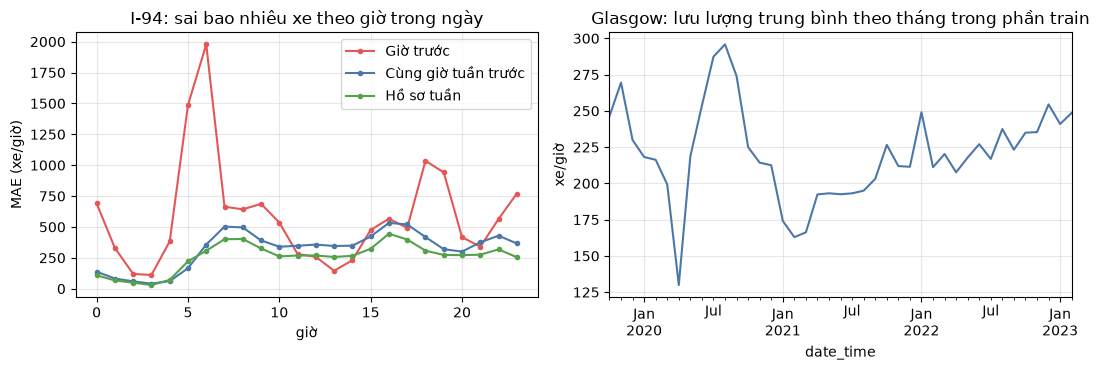

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
actual, forecasts, _ = data["I-94 (cao tốc)"]
hour = actual.index.hour
for method, color in (("Giờ trước", "#E45756"), ("Cùng giờ tuần trước", "#4C78A8"), ("Hồ sơ tuần", "#54A24B")):
    (actual - forecasts[method]).abs().groupby(hour).mean().plot(ax=axes[0], marker="o", ms=3, label=method, color=color)
axes[0].set_title("I-94: sai bao nhiêu xe theo giờ trong ngày")
axes[0].set_xlabel("giờ"); axes[0].set_ylabel("MAE (xe/giờ)"); axes[0].legend(); axes[0].grid(alpha=0.3)

glasgow_train = data["Glasgow GD1351_R (đường phố)"][2]
glasgow_train.resample("MS").mean().plot(ax=axes[1], color="#4C78A8")
axes[1].set_title("Glasgow: lưu lượng trung bình theo tháng trong phần train")
axes[1].set_ylabel("xe/giờ"); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Đọc kết quả.**
- **Trái:** "Giờ trước" sai rất nặng lúc **5–6 giờ sáng** và **18–19 giờ** — đúng lúc lưu lượng tăng hoặc giảm nhanh. Ban đêm thì nó không tệ. Đây là lý do model của dự án cần cả lag 1 giờ lẫn lag 168 giờ và đặc trưng theo giờ trong ngày.
- **Phải:** phần train của Glasgow có cả **giai đoạn COVID-19**: lưu lượng tụt từ mùa xuân 2020 và cả năm 2021 thấp nhất (trung bình năm 194 xe/giờ, so với 242 của 2019). "Hồ sơ tuần" lấy trung bình cả giai đoạn đó nên đoán **thấp hơn thực tế** của năm 2023 (trung bình thấp hơn khoảng 29 xe/giờ). "Cùng giờ tuần trước" chỉ nhìn tuần gần nhất nên không bị ảnh hưởng.
- **Bài học:** cách dựa trên lịch sử dài bị "kéo" bởi những thay đổi trong quá khứ — đây chính là **drift**, chủ đề của giai đoạn 5.

### MASE — đo "so với cách đoán ngây thơ"

**Đang làm gì.** Ở bước 3.1, MAE không so được giữa nơi đông và nơi vắng. Hyndman & Koehler đề xuất **chia sai số cho sai số của một cách đoán đơn giản tính trên phần train** (sách FPP3, mục 5.8). Với dữ liệu có chu kỳ, cách đơn giản là đoán ngây thơ theo mùa — ở đây là "cùng giờ tuần trước" (chu kỳ 168 giờ).

**MASE = MAE trên phần test ÷ MAE của "cùng giờ tuần trước" tính trên phần train.** MASE < 1 nghĩa là tốt hơn mức sai thường gặp của cách đoán tuần trước.

> **Đoán trước:** MASE của chính cách "Cùng giờ tuần trước" có bằng đúng 1 không?

I-94 (cao tốc): mẫu số MASE = 339.7 xe/giờ
Glasgow GD1351_R (đường phố): mẫu số MASE = 37.6 xe/giờ


MAE  \
I-94 (cao tốc)               Trung bình kỳ train  1727.18   
                             Hồ sơ tuần            258.50   
                             Giờ trước             591.35   
                             Cùng giờ hôm qua      561.93   
                             Cùng giờ tuần trước   323.33   
Glasgow GD1351_R (đường phố) Trung bình kỳ train    70.73   
                             Hồ sơ tuần             39.26   
                             Giờ trước              39.04   
                             Cùng giờ hôm qua       42.69   
                             Cùng giờ tuần trước    19.88   

                                                  MASE (mẫu số từ train)  \
I-94 (cao tốc)               Trung bình kỳ train                    5.08   
                             Hồ sơ tuần                             0.76   
                             Giờ trước                              1.74   
                             Cùng giờ hôm qua                       1.65   
                             Cùng giờ tuần trước                    0.95   
Glasgow GD1351_R (đường phố) Trung bình kỳ train                    1.88   
                             Hồ sơ tuần                             1.04   
                             Giờ trước                              1.04   
                             Cùng giờ hôm qua                       1.14   
                             Cùng giờ tuần trước                    0.53   

                                                  MAE ÷ MAE tuần trước (cùng giờ test)  
I-94 (cao tốc)               Trung bình kỳ train                                  5.34  
                             Hồ sơ tuần                                           0.80  
                             Giờ trước                                            1.83  
                             Cùng giờ hôm qua                                     1.74  
                             Cùng giờ tuần trước                                  1.00  
Glasgow GD1351_R (đường phố) Trung bình kỳ train                                  3.56  
                             Hồ sơ tuần                                           1.97  
                             Giờ trước                                            1.96  
                             Cùng giờ hôm qua                                     2.15  
                             Cùng giờ tuần trước                                  1.00

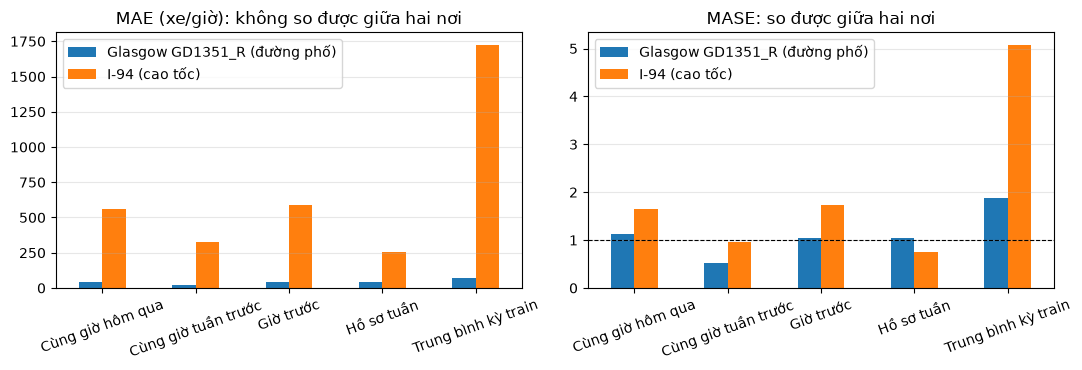

In [10]:
def mase_scale(train, season=168):
    """MAE của cách đoán 'cùng giờ chu kỳ trước' trên phần train (chỉ các cặp giờ đều có dữ liệu)."""
    return (train - train.shift(season)).abs().mean()

rows = {}
for name, (actual, forecasts, train) in data.items():
    scale = mase_scale(train)
    weekly_mae = (actual - forecasts["Cùng giờ tuần trước"]).abs().mean()
    for method in forecasts:
        mae = (actual - forecasts[method]).abs().mean()
        rows[(name, method)] = {"MAE": mae, "MASE (mẫu số từ train)": mae / scale,
                                "MAE ÷ MAE tuần trước (cùng giờ test)": mae / weekly_mae}
    print(f"{name}: mẫu số MASE = {scale:.1f} xe/giờ")
table = pd.DataFrame(rows).T
with pd.option_context("display.precision", 2):
    display(table)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, column, title in ((axes[0], "MAE", "MAE (xe/giờ): không so được giữa hai nơi"),
                          (axes[1], "MASE (mẫu số từ train)", "MASE: so được giữa hai nơi")):
    table[column].unstack(0).plot.bar(ax=ax, rot=20)
    ax.set_title(title); ax.grid(axis="y", alpha=0.3); ax.set_xlabel("")
axes[1].axhline(1, color="black", lw=0.8, ls="--")
plt.tight_layout(); plt.show()

**Đọc kết quả.**
- Ở biểu đồ trái, cột Glasgow gần như biến mất vì Glasgow ít xe hơn ~15 lần: **MAE không so được giữa hai nơi**. Ở biểu đồ phải (MASE), hai nơi nằm cùng một thang và so được.
- MASE của "Cùng giờ tuần trước" **không bằng 1**: 0,95 ở I‑94 và chỉ **0,53 ở Glasgow**. Vì mẫu số tính trên **phần train**, mà phần train của Glasgow có COVID (tuần này khác hẳn tuần trước) nên mẫu số lớn, kéo MASE xuống. **Mẫu số phụ thuộc vào giai đoạn train** — cần ghi rõ khi so.
- Cột cuối so trực tiếp với cách đoán tuần trước **trên đúng các giờ test**, nên luôn bằng 1 cho chính nó và không bị giai đoạn train ảnh hưởng. Khi so các model **trên cùng một dataset**, con số này dễ đọc hơn: 0,80 nghĩa là sai ít hơn 20% so với cách đoán tuần trước.

---
## Tóm tắt bước 3.2

**Mốc mà model của dự án phải vượt ở bước 3.3** (cách đoán ngây thơ tốt nhất trên phần test 15% cuối):

| Dataset | Cách ngây thơ tốt nhất | MAE | WAPE | R² |
| --- | --- | --- | --- | --- |
| I‑94 (cao tốc) | Hồ sơ tuần | ≈ 259 xe/giờ | ≈ 7,7% | ≈ 0,949 |
| Glasgow GD1351_R (đường phố) | Cùng giờ tuần trước | ≈ 20 xe/giờ | ≈ 7,9% | ≈ 0,878 |

**Bài học về phương pháp**
1. **Luôn có mốc so sánh đơn giản**, đo trên cùng tập giờ test. Một con số đứng một mình (R² = 0,94) không nói được là tốt hay xấu.
2. **Thử nhiều mốc**: cách đơn giản nào mạnh nhất phụ thuộc vào dữ liệu (cao tốc khác đường phố).
3. **Mốc so sánh dựa trên lịch sử dài cũng bị drift làm hỏng** (Glasgow có COVID trong phần train).
4. Chỉ số "so với mốc" (MASE, hoặc tỉ lệ MAE so với mốc trên cùng giờ test) **giải quyết vấn đề quy mô** của bước 3.1 — nhưng phải ghi rõ mốc là gì và tính trên giai đoạn nào.

**Câu hỏi mang sang bước 3.3:** 5 model của dự án (RandomForest, XGBoost, LightGBM, LSTM, GRU) có vượt được mốc này không? Và chạy trên máy có ra đúng như trên hệ thống không?

**Tự thử:** đổi `TEST_SHARE` thành 0.30, hoặc đổi Glasgow sang `GD1501_A`/`GD0801_A` trong `DATASETS`, rồi chạy lại các ô của bước 3.2.

---
**Nguồn:** Hyndman & Athanasopoulos, *Forecasting: Principles and Practice*, 3rd ed, mục 5.8 (scaled errors, MASE; seasonal naïve), https://otexts.com/fpp3/accuracy.html (đọc 26/11/2026).

---
## Bước 3.3 — Chạy model thật của dự án và đối chiếu với hệ thống

**Đang làm gì.** Train 5 model của dự án **trên máy**, bằng **chính mã của dự án** và **đúng cấu hình** của website (3 fold kiểm tra chéo, 15% cuối làm test, 3 epoch cho LSTM/GRU, seed 42). Hai câu hỏi:
1. **Thí nghiệm trên máy có giống hệ thống không?** — chạy lại đúng lượt `f93d0351` (Hồ Chí Minh, cửa sổ 2024–2026) và so với số hệ thống đã lưu.
2. **Model có vượt mốc ngây thơ của bước 3.2 không?** — trên I‑94, Glasgow và Hồ Chí Minh.

Train tốn từ 5 đến 26 phút mỗi dataset nên **không chạy trong notebook**; nó chạy bằng script, notebook chỉ đọc kết quả:

```bash
python experiments/scripts/e1_run_models.py hcm_verify_f93d0351 data/synthetic/TrafficVolumeData_HCM_2015_2030_synthetic.csv 2024-01-01 2026-01-01 <thư mục tạm>
python experiments/scripts/e1_run_models.py i94_full data/real/i94-minneapolis/TrafficVolumeData_I94_Minneapolis_2012_2018.csv 2012-10-02 2018-10-01 <thư mục tạm> --patch-median-round
python experiments/scripts/e1_run_models.py glasgow_GD1351_R data/real/glasgow/TrafficVolumeData_Glasgow_GD1351_R_2019_2023.csv 2019-10-01 2023-10-01 <thư mục tạm>
```

**Ba nhóm model** (khi đọc mã mới biết hệ thống có hai cách train cây):

| Nhóm | Mã được gọi | Học từ |
| --- | --- | --- |
| Cây của hệ thống (RandomForest, XGBoost, LightGBM) | `src.pipeline.run_pipeline` — đúng hàm nhánh cây trên Kaggle gọi | **Chỉ thời tiết và lịch** (giờ, thứ, tháng, ngày lễ). **Không dùng số xe các giờ trước**, dù tên model có đuôi `_lag` |
| LSTM/GRU của hệ thống | `train_region_recurrent_candidate` | Chuỗi 72 giờ trước (có số xe) |
| Cây có lag (**hệ thống không dùng**) | `train_region_tree_lag_candidates` — có sẵn trong mã | Thời tiết, lịch **và** số xe 1–168 giờ trước |

> **Đoán trước:** cây của hệ thống không biết số xe gần đây. Ở Glasgow — nơi phần train có COVID — nó sẽ tốt hơn hay kém hơn cách "lấy cùng giờ tuần trước"?

In [11]:
import json

OUT = ROOT / "experiments/outputs/e1"
SYSTEM_F93D0351 = {  # sai số hệ thống đã lưu cho lượt f93d0351 (đọc DB chỉ đọc, 26/11/2026)
    "RandomForest": (341.5757, 306.9402), "XGBoost": (349.5603, None), "LightGBM": (346.1207, None),
    "LSTM": (512.67, 319.7594), "GRU": (459.4409, 328.4709),
}
local = json.loads((OUT / "hcm_verify_f93d0351" / "summary.json").read_text(encoding="utf-8"))
verify = pd.DataFrame([
    {"Model": model, "CV MAE hệ thống": cv, "CV MAE trên máy": local["models"][model]["cv_MAE_mean"],
     "Lệch CV (%)": (local["models"][model]["cv_MAE_mean"] / cv - 1) * 100,
     "Test MAE hệ thống": test, "Test MAE trên máy": local["models"][model]["test_MAE"]}
    for model, (cv, test) in SYSTEM_F93D0351.items()
]).set_index("Model")
with pd.option_context("display.precision", 4):
    display(verify)
print("Thư viện trên máy:", local["versions"])

,CV MAE hệ thống,CV MAE trên máy,Lệch CV (%),Test MAE hệ thống,Test MAE trên máy
Model,,,,,
RandomForest,341.5757,341.5757,0.0000,306.9402,306.9402
XGBoost,349.5603,350.1634,0.1725,NaN,305.5820
LightGBM,346.1207,346.1207,0.0000,NaN,307.7463
LSTM,512.6700,512.6700,0.0000,319.7594,319.7594
GRU,459.4409,458.6430,-0.1737,328.4709,328.4709


Thư viện trên máy: {'python': '3.11.9', 'numpy': '2.4.4', 'pandas': '3.0.2', 'scikit-learn': '1.8.0', 'xgboost': '3.2.0', 'lightgbm': '4.7.0', 'tensorflow': '2.21.0'}


**Đọc kết quả.**
- **RandomForest, LightGBM và LSTM trùng hệ thống đến chữ số cuối** (ví dụ RandomForest CV 341,5757, test 306,9402). Như vậy thí nghiệm trên máy **phản ánh đúng** cái đang chạy trên website.
- **XGBoost và CV của GRU lệch khoảng 0,17%**; test của GRU vẫn trùng. Giả thuyết: phiên bản thư viện trên Kaggle khác trên máy (máy: xgboost 3.2.0, TensorFlow 2.21.0) — **chưa kiểm**, ghi là giới hạn.
- XGBoost và LightGBM trên hệ thống không có test MAE: pipeline chỉ chấm phần test cho model thắng. Thí nghiệm chấm cả ba bằng đúng các hàm của pipeline (với model thắng, số tự chấm trùng số của pipeline: 306,9402).

In [12]:
RUNS = {"I-94 (cao tốc)": ("i94_full", "data/real/i94-minneapolis/TrafficVolumeData_I94_Minneapolis_2012_2018.csv"),
        "Glasgow GD1351_R (đường phố)": ("glasgow_GD1351_R", "data/real/glasgow/TrafficVolumeData_Glasgow_GD1351_R_2019_2023.csv"),
        "Hồ Chí Minh (giả lập)": ("hcm_verify_f93d0351", "data/synthetic/TrafficVolumeData_HCM_2015_2030_synthetic.csv")}
GROUP = {"RandomForest": "Cây của hệ thống", "XGBoost": "Cây của hệ thống", "LightGBM": "Cây của hệ thống",
         "LSTM": "LSTM/GRU của hệ thống", "GRU": "LSTM/GRU của hệ thống"}

def score(actual, forecast, scale):
    e = actual - forecast
    return {"MAE": e.abs().mean(), "RMSE": np.sqrt((e ** 2).mean()),
            "WAPE (%)": e.abs().sum() / actual.abs().sum() * 100,
            "R²": 1 - (e ** 2).sum() / ((actual - actual.mean()) ** 2).sum(), "MASE": e.abs().mean() / scale}

tables, predictions_by_run = {}, {}
for label, (run, data_file) in RUNS.items():
    summary = json.loads((OUT / run / "summary.json").read_text(encoding="utf-8"))
    predictions = {model: pd.read_csv(OUT / run / f"{model}_final_test_predictions.csv", parse_dates=["date_time"])
                           .set_index("date_time")["prediction"]
                   for model in summary["models"] if not model.startswith("_")}
    common = sorted(set.intersection(*(set(series.index) for series in predictions.values())))  # cùng giờ test
    volume = load_volume(data_file)
    hourly = volume.asfreq("h")
    history = hourly[(hourly.index < min(common)) & (hourly.index >= pd.Timestamp(summary["config"]["train_start_date"]))]
    profile = history.groupby([history.index.dayofweek, history.index.hour]).mean()
    naive = pd.DataFrame({"Mốc: cùng giờ tuần trước": hourly.shift(168).reindex(common).to_numpy(),
                          "Mốc: hồ sơ tuần": [profile.get((t.dayofweek, t.hour)) for t in common]},
                         index=pd.DatetimeIndex(common))
    times = naive.index[naive.notna().all(axis=1)]
    actual = volume.reindex(times)
    scale = (history - history.shift(168)).abs().mean()            # mẫu số MASE, tính trên phần trước test
    table = {name: score(actual, naive.loc[times, name], scale) for name in naive}
    table.update({model: score(actual, series.reindex(times), scale) for model, series in predictions.items()})
    table = pd.DataFrame(table).T
    table["MAE ÷ mốc tốt nhất"] = table["MAE"] / table.loc[[n for n in table.index if n.startswith("Mốc")], "MAE"].min()
    table.insert(0, "Nhóm", ["Mốc ngây thơ" if n.startswith("Mốc") else GROUP.get(n, "Cây có lag (hệ thống không dùng)")
                             for n in table.index])
    tables[label], predictions_by_run[label] = table, (actual, predictions)
    print(f"{label}: {len(times):,} giờ test chung, {times.min():%d/%m/%Y} – {times.max():%d/%m/%Y}"
          + ("  [có vá tạm: làm tròn trung vị khi lấp giờ thiếu]" if summary.get("patches") else ""))
    with pd.option_context("display.precision", 3):
        display(table[["Nhóm", "MAE", "WAPE (%)", "R²", "MASE", "MAE ÷ mốc tốt nhất"]])

I-94 (cao tốc): 6,044 giờ test chung, 20/01/2018 – 30/09/2018  [có vá tạm: làm tròn trung vị khi lấp giờ thiếu]


,Nhóm,MAE,WAPE (%),R²,MASE,MAE ÷ mốc tốt nhất
Mốc: cùng giờ tuần trước,Mốc ngây thơ,322.505,9.628,0.900,0.949,1.249
Mốc: hồ sơ tuần,Mốc ngây thơ,258.172,7.708,0.949,0.760,1.000
RandomForest,Cây của hệ thống,226.474,6.761,0.964,0.667,0.877
XGBoost,Cây của hệ thống,220.314,6.577,0.969,0.649,0.853
LightGBM,Cây của hệ thống,215.953,6.447,0.970,0.636,0.836
LSTM,LSTM/GRU của hệ thống,234.463,7.000,0.974,0.690,0.908
GRU,LSTM/GRU của hệ thống,252.747,7.546,0.971,0.744,0.979
RandomForest (lag),Cây có lag (hệ thống không dùng),144.973,4.328,0.987,0.427,0.562
XGBoost (lag),Cây có lag (hệ thống không dùng),138.793,4.144,0.988,0.409,0.538
LightGBM (lag),Cây có lag (hệ thống không dùng),142.018,4.240,0.988,0.418,0.550


Glasgow GD1351_R (đường phố): 4,783 giờ test chung, 17/02/2023 – 30/09/2023


,Nhóm,MAE,WAPE (%),R²,MASE,MAE ÷ mốc tốt nhất
Mốc: cùng giờ tuần trước,Mốc ngây thơ,19.891,7.966,0.878,0.529,1.000
Mốc: hồ sơ tuần,Mốc ngây thơ,39.196,15.698,0.628,1.043,1.971
RandomForest,Cây của hệ thống,43.988,17.617,0.525,1.170,2.211
XGBoost,Cây của hệ thống,45.469,18.210,0.495,1.210,2.286
LightGBM,Cây của hệ thống,45.046,18.040,0.503,1.199,2.265
LSTM,LSTM/GRU của hệ thống,27.878,11.165,0.809,0.742,1.402
GRU,LSTM/GRU của hệ thống,27.851,11.154,0.807,0.741,1.400
RandomForest (lag),Cây có lag (hệ thống không dùng),17.181,6.881,0.919,0.457,0.864
XGBoost (lag),Cây có lag (hệ thống không dùng),17.098,6.848,0.922,0.455,0.860
LightGBM (lag),Cây có lag (hệ thống không dùng),17.809,7.132,0.917,0.474,0.895


Hồ Chí Minh (giả lập): 2,632 giờ test chung, 13/09/2025 – 31/12/2025


,Nhóm,MAE,WAPE (%),R²,MASE,MAE ÷ mốc tốt nhất
Mốc: cùng giờ tuần trước,Mốc ngây thơ,389.793,10.750,0.924,0.890,1.189
Mốc: hồ sơ tuần,Mốc ngây thơ,327.712,9.038,0.942,0.748,1.000
RandomForest,Cây của hệ thống,306.940,8.465,0.951,0.701,0.937
XGBoost,Cây của hệ thống,305.582,8.428,0.952,0.698,0.932
LightGBM,Cây của hệ thống,307.746,8.488,0.953,0.703,0.939
LSTM,LSTM/GRU của hệ thống,319.759,8.819,0.957,0.730,0.976
GRU,LSTM/GRU của hệ thống,328.471,9.059,0.952,0.750,1.002
RandomForest (lag),Cây có lag (hệ thống không dùng),229.345,6.325,0.970,0.524,0.700
XGBoost (lag),Cây có lag (hệ thống không dùng),224.253,6.185,0.972,0.512,0.684
LightGBM (lag),Cây có lag (hệ thống không dùng),229.015,6.316,0.971,0.523,0.699


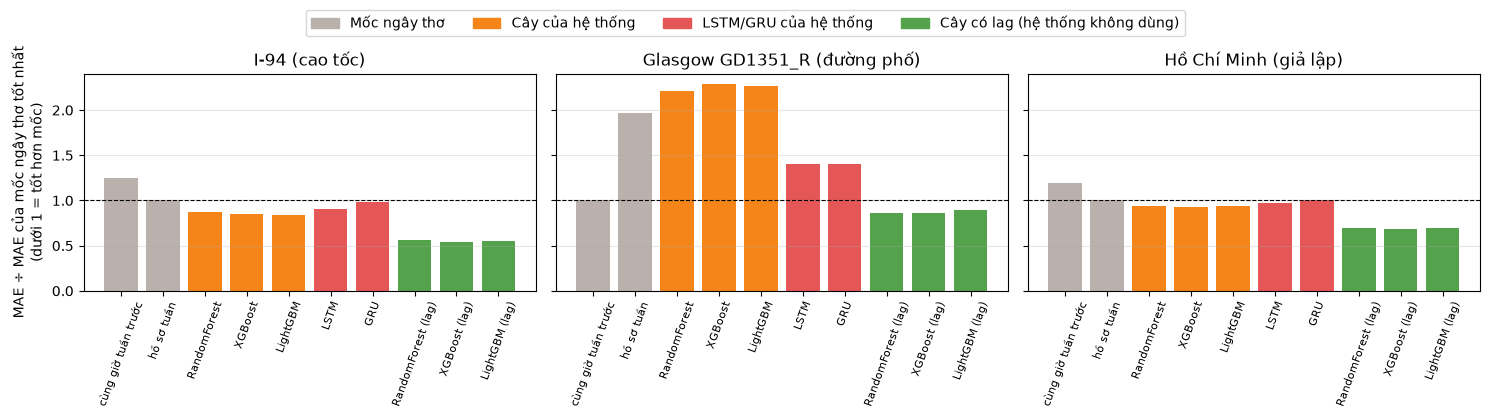

In [13]:
colors = {"Mốc ngây thơ": "#BAB0AC", "Cây của hệ thống": "#F58518",
          "LSTM/GRU của hệ thống": "#E45756", "Cây có lag (hệ thống không dùng)": "#54A24B"}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, (label, table) in zip(axes, tables.items()):
    ax.bar(range(len(table)), table["MAE ÷ mốc tốt nhất"], color=[colors[g] for g in table["Nhóm"]])
    ax.axhline(1, color="black", lw=0.8, ls="--")
    ax.set_xticks(range(len(table)))
    ax.set_xticklabels([n.replace("Mốc: ", "") for n in table.index], rotation=70, fontsize=8)
    ax.set_title(label); ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("MAE ÷ MAE của mốc ngây thơ tốt nhất\n(dưới 1 = tốt hơn mốc)")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()]
fig.legend(handles, colors.keys(), loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.0))
plt.tight_layout(rect=(0, 0, 1, 0.92)); plt.show()

**Đọc kết quả** (mọi so sánh trên **cùng các giờ test** của mỗi dataset).

| Dataset | Mốc ngây thơ tốt nhất | Cây của hệ thống | LSTM / GRU của hệ thống | Cây có lag |
| --- | --- | --- | --- | --- |
| I‑94 (thật) | Hồ sơ tuần, MAE 258 | **Tốt hơn 12–16%** (MAE 216–226) | Tốt hơn 9% / 2% | **Tốt hơn 44–46%** (MAE 139–145) |
| Glasgow (thật) | Tuần trước, MAE 19,9 | **Kém hơn 2,2–2,3 lần** (MAE 44–45) | Kém hơn 1,4 lần (MAE 27,9) | **Tốt hơn 10–14%** (MAE 17,1–17,8) |
| Hồ Chí Minh (giả lập) | Hồ sơ tuần, MAE 328 | Tốt hơn 6–7% | Tốt hơn 2% / ngang mốc | Tốt hơn 30–32% |

- **Ở Glasgow, cả 5 model hệ thống đang dùng đều kém hơn cách "lấy số xe cùng giờ tuần trước".** Cây của hệ thống đoán **thấp hơn thực tế trung bình 33 xe/giờ**: không biết số xe gần đây, nó chỉ đoán theo mức trung bình của phần train — mà phần train có giai đoạn COVID. LSTM/GRU gần như không lệch mức (−3 xe/giờ) nhưng sai đều ở mọi giờ (mới học 3 epoch).
- **Cây có lag vượt mốc ở cả 3 dataset** (tốt hơn 10–46%) và không lệch mức (+0,7 xe/giờ ở Glasgow). Đây là mã đã có sẵn trong dự án nhưng hệ thống chưa dùng.
- **Mức "tốt" phụ thuộc nơi đo:** cây của hệ thống hơn mốc 12–16% ở I‑94 nhưng kém 2,2 lần ở Glasgow. Chỉ thử trên dữ liệu giả lập (hơn mốc 6–7%) sẽ không thấy điểm yếu này.
- **R² và MAE xếp hạng khác nhau:** ở I‑94, LSTM có R² cao nhất trong các model hệ thống (0,974) nhưng MAE lại kém LightGBM (234 so với 216). Bước 3.4 sẽ xem chỉ số nào đáng tin hơn khi chọn model.

### Ba phát hiện về hệ thống trong bước này

| # | Phát hiện | Bằng chứng | Hệ quả |
| --- | --- | --- | --- |
| 1 | **Cây của hệ thống không dùng số xe các giờ trước** | `scripts/cloud_training/execute_branch.py` nhánh `tree` gọi `src.pipeline.run_pipeline` (`legacy_sklearn`); danh sách feature của model đang dùng chỉ có thời tiết và lịch. Handoff 28/10 ghi đây là chủ ý giữ pipeline cũ. | Ở dữ liệu thật, cây có lag sai ít hơn 34–62% so với cây của hệ thống (I‑94 34–37%, Glasgow 60–62%). Đây là đề xuất cải tiến cần GVHD và người dùng cân nhắc, **chưa sửa**. |
| 2 | **Lỗi tiềm ẩn khi dataset có khoảng thiếu dài** | `src/time_series_features.py:37` lấp giờ thiếu bằng trung vị; trung vị lẻ (vd 3.456,5) không ghi được vào cột số nguyên → `TypeError`, cả ở pandas 2.3.3 (bản của image) lẫn 3.0.2. I‑94 có 286 giờ như vậy. | Train LSTM/GRU (và cây có lag) sẽ hỏng với dataset có khoảng thiếu dài. Hai dataset thành phố hiện tại đủ giờ nên chưa gặp. Thí nghiệm dùng **vá tạm** (làm tròn trung vị) chỉ trong script; cần một PR để sửa thật. |
| 3 | **MAPE trong báo cáo train của hệ thống vô nghĩa** | Lượt `f93d0351` lưu `validation_MAPE` ≈ 2,66·10¹⁷ (dataset có giờ 0 xe) — đúng như thí nghiệm B của bước 3.1. | Không nên dùng hay hiển thị MAPE. |

---
## Tóm tắt bước 3.3

1. **Thí nghiệm trên máy giống hệ thống** (3/5 model trùng đến chữ số cuối, 2 model lệch 0,17%), nên các kết luận offline áp dụng được cho website.
2. **So với mốc ngây thơ**, model của hệ thống "tốt" hay "tệ" tùy nơi: tốt hơn ở I‑94, kém hơn hẳn ở Glasgow. Một con số tuyệt đối (MAE, R²) đứng riêng không cho thấy điều này.
3. Phương án **cây có lag** (đã có trong mã) vượt mốc ở cả 3 dataset.

**Bài học về phương pháp**
1. **Đối chiếu với hệ thống thật trước khi kết luận.** Nhờ bước này mới phát hiện mình gọi nhầm đường train cây; nếu bỏ qua, mọi kết luận về cây sẽ sai.
2. **Đọc mã để biết hệ thống thật sự làm gì**, đừng tin tên gọi (`random_forest_lag` mà không dùng lag).
3. **Thử trên dữ liệu thật, nhiều nơi**: dữ liệu giả lập "êm" che mất cả điểm yếu của model (Glasgow) lẫn lỗi xử lý dữ liệu (khoảng thiếu dài của I‑94).
4. Khi phải sửa tạm để thí nghiệm chạy được, **ghi rõ đã sửa gì và chỉ sửa ở thí nghiệm**, không âm thầm đổi mã hệ thống.

**Câu hỏi mang sang bước 3.4:** với 8 model × 3 dataset này, chỉ số nào (MAE, RMSE, WAPE, R², MASE, so với mốc) **xếp hạng model đúng và ổn định nhất**, và chỉ số nào nên hiển thị cho admin ở tab Model Quality?

**Tự thử:** trong ô bảng so sánh, đổi `RUNS` chỉ còn một dataset hoặc thêm cột `RMSE` vào danh sách hiển thị, chạy lại và xem thứ hạng các model có đổi không.

---
## Bước 3.4 — Chấm các thước đo

**Đang làm gì.** Đến đây ta có 10 cách dự đoán (2 mốc ngây thơ, 5 model hệ thống, 3 cây có lag) trên 3 dataset. Bây giờ **đổi vai**: không chấm model nữa mà **chấm 7 chỉ số** (MAE, RMSE, WAPE, MASE, R², MAPE, sMAPE) bằng 4 phép thử định lượng:

| Phép thử | Câu hỏi | Tiêu chí ở khung 7 bước |
| --- | --- | --- |
| A. Thứ hạng | Các chỉ số có xếp hạng 10 cách dự đoán giống nhau không? | Chỉ số nào thực chất là "cùng một loại" |
| B. So giữa các nơi | Cùng một chỉ số có cùng ý nghĩa ở cao tốc (≈ 3.300 xe/giờ) và đường phố (≈ 250 xe/giờ) không? | So được giữa các vùng |
| C. Độ ổn định | Lấy ngẫu nhiên lại các ngày test 1.000 lần: model thắng có còn thắng không? | Kết luận không phụ thuộc may rủi |
| D. Giờ nào quyết định | Mỗi chỉ số chịu ảnh hưởng bao nhiêu từ giờ đêm, bao nhiêu từ giờ cao điểm? | Chỉ số "để ý" đúng chỗ mình quan tâm |

> **Đoán trước:**
> 1. MAE và WAPE có bao giờ chọn ra hai model thắng khác nhau trên cùng một dataset không?
> 2. R² và RMSE thì sao?
> 3. Chỉ số nào bị giờ đêm (rất ít xe) chi phối nhiều nhất?

In [14]:
from scipy.stats import kendalltau

METRICS = ["MAE", "WAPE", "MASE", "RMSE", "R²", "MAPE", "sMAPE"]
LOWER_IS_BETTER = {"MAE": True, "WAPE": True, "MASE": True, "RMSE": True, "R²": False, "MAPE": True, "sMAPE": True}

def all_metrics(y, p, scale):
    e = y - p
    positive = y > 0
    return {"MAE": np.mean(np.abs(e)), "WAPE": np.abs(e).sum() / y.sum() * 100, "MASE": np.mean(np.abs(e)) / scale,
            "RMSE": np.sqrt(np.mean(e ** 2)), "R²": 1 - (e ** 2).sum() / ((y - y.mean()) ** 2).sum(),
            "MAPE": np.mean(np.abs(e[positive]) / y[positive]) * 100,
            "sMAPE": np.mean(2 * np.abs(e) / (np.abs(y) + np.abs(p))) * 100}

# Bảng dự đoán trên cùng các giờ test, dựng từ kết quả bước 3.3 (mốc ngây thơ + 8 model).
frames = {}
for label, (run, data_file) in RUNS.items():
    actual, predictions = predictions_by_run[label]
    volume = load_volume(data_file)
    hourly = volume.asfreq("h")
    summary = json.loads((OUT / run / "summary.json").read_text(encoding="utf-8"))
    history = hourly[(hourly.index < actual.index.min()) & (hourly.index >= pd.Timestamp(summary["config"]["train_start_date"]))]
    profile = history.groupby([history.index.dayofweek, history.index.hour]).mean()
    frame = pd.DataFrame({"actual": actual.to_numpy(),
                          "Mốc: tuần trước": hourly.shift(168).reindex(actual.index).to_numpy(),
                          "Mốc: hồ sơ tuần": [profile.get((t.dayofweek, t.hour)) for t in actual.index]},
                         index=actual.index)
    for model, series in predictions.items():
        frame[model] = series.reindex(actual.index).to_numpy()
    frames[label] = (frame, (history - history.shift(168)).abs().mean())
print({label: f"{len(frame):,} giờ, {int((frame['actual'] == 0).sum())} giờ 0 xe" for label, (frame, _) in frames.items()})

{'I-94 (cao tốc)': '6,044 giờ, 0 giờ 0 xe', 'Glasgow GD1351_R (đường phố)': '4,783 giờ, 0 giờ 0 xe', 'Hồ Chí Minh (giả lập)': '2,632 giờ, 0 giờ 0 xe'}


### A. Các chỉ số có xếp hạng giống nhau không?

Với mỗi dataset, xếp hạng 10 cách dự đoán theo từng chỉ số (1 = tốt nhất), rồi đo **độ giống nhau của hai bảng xếp hạng** bằng hệ số Kendall τ: 1 = giống hệt, 0 = không liên quan.

I-94 (cao tốc)


,MAE,WAPE,MASE,RMSE,R²,MAPE,sMAPE
Mốc: tuần trước,10,10,10,10,10,9,8
Mốc: hồ sơ tuần,9,9,9,9,9,7,6
RandomForest,6,6,6,8,8,5,4
XGBoost,5,5,5,7,7,6,7
LightGBM,4,4,4,6,6,4,5
LSTM,7,7,7,4,4,8,9
GRU,8,8,8,5,5,10,10
RandomForest (lag),3,3,3,3,3,2,2
XGBoost (lag),1,1,1,1,1,1,1
LightGBM (lag),2,2,2,2,2,3,3


Glasgow GD1351_R (đường phố)


,MAE,WAPE,MASE,RMSE,R²,MAPE,sMAPE
Mốc: tuần trước,4,4,4,4,4,4,4
Mốc: hồ sơ tuần,7,7,7,7,7,7,7
RandomForest,8,8,8,8,8,8,8
XGBoost,10,10,10,10,10,10,10
LightGBM,9,9,9,9,9,9,9
LSTM,6,6,6,5,5,5,5
GRU,5,5,5,6,6,6,6
RandomForest (lag),2,2,2,2,2,1,1
XGBoost (lag),1,1,1,1,1,2,2
LightGBM (lag),3,3,3,3,3,3,3


Hồ Chí Minh (giả lập)


,MAE,WAPE,MASE,RMSE,R²,MAPE,sMAPE
Mốc: tuần trước,10,10,10,10,10,8,8
Mốc: hồ sơ tuần,8,8,8,9,9,6,5
RandomForest,5,5,5,8,8,4,4
XGBoost,4,4,4,6,6,7,7
LightGBM,6,6,6,5,5,5,6
LSTM,7,7,7,4,4,9,9
GRU,9,9,9,7,7,10,10
RandomForest (lag),3,3,3,3,3,1,1
XGBoost (lag),1,1,1,1,1,2,2
LightGBM (lag),2,2,2,2,2,3,3


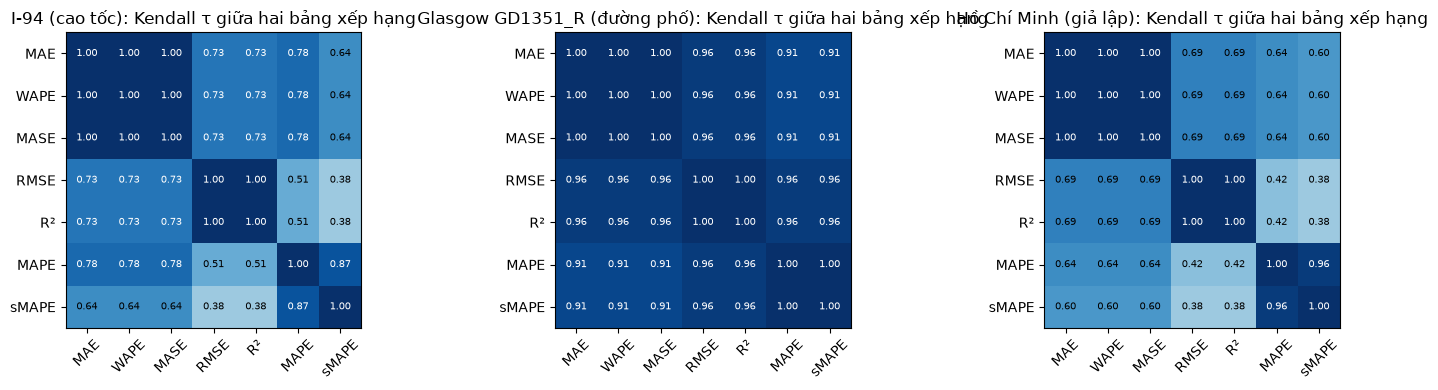

In [15]:
rank_tables, tau_tables = {}, {}
for label, (frame, scale) in frames.items():
    y = frame["actual"].to_numpy()
    values = pd.DataFrame({name: all_metrics(y, frame[name].to_numpy(), scale) for name in frame.columns[1:]}).T
    ranks = pd.DataFrame({m: values[m].rank(ascending=LOWER_IS_BETTER[m]).astype(int) for m in METRICS})
    rank_tables[label] = ranks
    tau_tables[label] = pd.DataFrame({a: {b: kendalltau(ranks[a], ranks[b]).statistic for b in METRICS} for a in METRICS})
    print(label); display(ranks)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (label, tau) in zip(axes, tau_tables.items()):
    image = ax.imshow(tau.to_numpy(), vmin=0, vmax=1, cmap="Blues")
    ax.set_xticks(range(len(METRICS))); ax.set_xticklabels(METRICS, rotation=45)
    ax.set_yticks(range(len(METRICS))); ax.set_yticklabels(METRICS)
    for i in range(len(METRICS)):
        for j in range(len(METRICS)):
            ax.text(j, i, f"{tau.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if tau.iloc[i, j] > 0.7 else "black")
    ax.set_title(f"{label}: Kendall τ giữa hai bảng xếp hạng")
plt.tight_layout(); plt.show()

**Đọc kết quả.**
- Trên **cùng một dataset**, **MAE, WAPE, MASE xếp hạng y hệt nhau** (τ = 1,00): WAPE và MASE chỉ là MAE chia cho một hằng số (tổng lưu lượng, mẫu số MASE). **RMSE và R² cũng y hệt nhau**: R² = 1 − (tổng e²)/(một hằng số của dữ liệu test), tức là **"RMSE đội lốt"**.
- Vậy 7 chỉ số thực chất chỉ là **3 họ**: **họ |e|** (MAE, WAPE, MASE) · **họ e²** (RMSE, R²) · **họ phần trăm từng giờ** (MAPE, sMAPE).
- Các họ **có thể xếp hạng khác nhau khá nhiều**: ở I‑94, τ giữa họ |e| và họ e² là 0,73; giữa họ e² và sMAPE chỉ 0,38. Ví dụ: LSTM đứng **thứ 7** theo MAE nhưng **thứ 4** theo RMSE/R² (ít lần sai rất nặng, nhưng hay sai vừa phải); GRU đứng **chót** theo MAPE ở I‑94 và Hồ Chí Minh.
- **Nhóm dẫn đầu không đổi**: 3 cây có lag luôn ở hạng 1–3 theo mọi chỉ số, ở cả 3 dataset. Khi một kết luận đúng theo mọi thước đo, nó rất chắc chắn; khi các thước đo bất đồng (ở giữa bảng), **chọn thước đo nào là chọn loại sai số nào mình quan tâm**.

### B. Cùng một chỉ số có cùng ý nghĩa ở các nơi không?

So 3 cách dự đoán trên cả 3 dataset: model hệ thống tốt nhất (LightGBM), mốc "tuần trước", và cây có lag tốt nhất (XGBoost có lag).

In [16]:
rows = []
for label, (frame, scale) in frames.items():
    y = frame["actual"].to_numpy()
    for name in ("LightGBM", "Mốc: tuần trước", "XGBoost (lag)"):
        rows.append({"Dataset": label, "Cách dự đoán": name, **all_metrics(y, frame[name].to_numpy(), scale)})
comparison = pd.DataFrame(rows).set_index(["Cách dự đoán", "Dataset"]).sort_index()
with pd.option_context("display.precision", 3):
    display(comparison[METRICS])

MAE    WAPE   MASE     RMSE  \
Cách dự đoán    Dataset                                                         
LightGBM        Glasgow GD1351_R (đường phố)   45.046  18.040  1.199   57.222   
                Hồ Chí Minh (giả lập)         307.746   8.488  0.703  471.981   
                I-94 (cao tốc)                215.953   6.447  0.636  345.238   
Mốc: tuần trước Glasgow GD1351_R (đường phố)   19.891   7.966  0.529   28.331   
                Hồ Chí Minh (giả lập)         389.793  10.750  0.890  602.945   
                I-94 (cao tốc)                322.505   9.628  0.949  626.161   
XGBoost (lag)   Glasgow GD1351_R (đường phố)   17.098   6.848  0.455   22.611   
                Hồ Chí Minh (giả lập)         224.253   6.185  0.512  367.048   
                I-94 (cao tốc)                138.793   4.144  0.409  213.598   

                                                 R²    MAPE   sMAPE  
Cách dự đoán    Dataset                                              
LightGBM        Glasgow GD1351_R (đường phố)  0.503  19.720  23.028  
                Hồ Chí Minh (giả lập)         0.953  10.860  10.675  
                I-94 (cao tốc)                0.970   9.705   9.061  
Mốc: tuần trước Glasgow GD1351_R (đường phố)  0.878   8.461   8.352  
                Hồ Chí Minh (giả lập)         0.924  12.512  11.999  
                I-94 (cao tốc)                0.900  13.094  11.850  
XGBoost (lag)   Glasgow GD1351_R (đường phố)  0.922   7.704   7.548  
                Hồ Chí Minh (giả lập)         0.972   8.006   7.736  
                I-94 (cao tốc)                0.988   5.960   5.724

**Đọc kết quả.**
- **MAE và RMSE không so được giữa các nơi**: LightGBM có MAE 216 ở I‑94 nhưng 45 ở Glasgow — con số nhỏ hơn ở Glasgow lại là model **tệ hơn nhiều** (xem dòng dưới).
- **WAPE so được và dễ nói**: LightGBM sai **6,4%** tổng lưu lượng ở I‑94, **8,5%** ở Hồ Chí Minh, **18,0%** ở Glasgow. Cây có lag: 4,1% / 6,2% / 6,8%. Người không biết dự án vẫn hiểu.
- **R² đánh lừa khi so giữa các nơi**: ở I‑94 mọi cách đều có R² từ khoảng 0,90 trở lên (kể cả cách đoán tuần trước), còn ở Glasgow cây có lag sai chỉ 6,8% mà R² là 0,92, LightGBM sai 18% thì R² 0,50. R² phụ thuộc dữ liệu dao động nhiều hay ít, không chỉ phụ thuộc model.
- **MASE so được, nhưng mẫu số tùy giai đoạn train**: cách đoán tuần trước có MASE 0,95 ở I‑94 mà 0,53 ở Glasgow (phần train Glasgow có COVID, đã thấy ở bước 3.2). Muốn nói "tốt hơn cách đơn giản bao nhiêu" thì so trực tiếp trên cùng giờ test (cột "MAE ÷ mốc tốt nhất" của bước 3.3) dễ hiểu hơn.

### C. Model thắng có còn thắng khi đổi các ngày test không?

**Đang làm gì.** Lấy ngẫu nhiên có hoàn lại các **ngày** trong phần test (giữ nguyên 24 giờ của mỗi ngày), 1.000 lần, mỗi lần tính lại các chỉ số. Đếm số lần model thắng (theo cả phần test) vẫn thắng, và đo độ giống của bảng xếp hạng so với ban đầu. Đây là cách xem kết luận có phụ thuộc vào vài ngày đặc biệt hay không.

> **Đoán trước:** họ chỉ số nào cho model thắng "vững" nhất?

In [17]:
rng = np.random.default_rng(0)
FAMILY = {"MAE": "|e|", "WAPE": "|e|", "MASE": "|e|", "RMSE": "e²", "R²": "e²", "MAPE": "phần trăm", "sMAPE": "phần trăm"}
stability = []
for label, (frame, scale) in frames.items():
    y = frame["actual"].to_numpy()
    names = list(frame.columns[1:])
    day_index = frame.index.normalize()
    days = [np.flatnonzero(day_index == day) for day in np.unique(day_index)]
    full = {m: pd.Series({n: all_metrics(y, frame[n].to_numpy(), scale)[m] for n in names}) for m in METRICS}
    winner = {m: (full[m].idxmin() if LOWER_IS_BETTER[m] else full[m].idxmax()) for m in METRICS}
    kept, taus = {m: 0 for m in METRICS}, {m: [] for m in METRICS}
    for _ in range(1000):
        pick = np.concatenate([days[i] for i in rng.integers(0, len(days), len(days))])
        sample = {n: all_metrics(y[pick], frame[n].to_numpy()[pick], scale) for n in names}
        for m in METRICS:
            values = pd.Series({n: sample[n][m] for n in names})
            kept[m] += (values.idxmin() if LOWER_IS_BETTER[m] else values.idxmax()) == winner[m]
            taus[m].append(kendalltau(values.rank(), full[m].rank()).statistic)
    for m in METRICS:
        stability.append({"Dataset": f"{label} ({len(days)} ngày)", "Chỉ số": m, "Họ": FAMILY[m],
                          "Model thắng": winner[m], "Giữ ngôi (%)": kept[m] / 10, "τ trung bình": np.mean(taus[m])})
stability = pd.DataFrame(stability).set_index(["Dataset", "Chỉ số"])
with pd.option_context("display.precision", 3):
    display(stability)

Họ         Model thắng  \
Dataset                                 Chỉ số                                  
I-94 (cao tốc) (254 ngày)               MAE           |e|       XGBoost (lag)   
                                        WAPE          |e|       XGBoost (lag)   
                                        MASE          |e|       XGBoost (lag)   
                                        RMSE           e²       XGBoost (lag)   
                                        R²             e²       XGBoost (lag)   
                                        MAPE    phần trăm       XGBoost (lag)   
                                        sMAPE   phần trăm       XGBoost (lag)   
Glasgow GD1351_R (đường phố) (204 ngày) MAE           |e|       XGBoost (lag)   
                                        WAPE          |e|       XGBoost (lag)   
                                        MASE          |e|       XGBoost (lag)   
                                        RMSE           e²       XGBoost (lag)   
                                        R²             e²       XGBoost (lag)   
                                        MAPE    phần trăm  RandomForest (lag)   
                                        sMAPE   phần trăm  RandomForest (lag)   
Hồ Chí Minh (giả lập) (110 ngày)        MAE           |e|       XGBoost (lag)   
                                        WAPE          |e|       XGBoost (lag)   
                                        MASE          |e|       XGBoost (lag)   
                                        RMSE           e²       XGBoost (lag)   
                                        R²             e²       XGBoost (lag)   
                                        MAPE    phần trăm  RandomForest (lag)   
                                        sMAPE   phần trăm  RandomForest (lag)   

                                                Giữ ngôi (%)  τ trung bình  
Dataset                                 Chỉ số                              
I-94 (cao tốc) (254 ngày)               MAE             99.9         0.974  
                                        WAPE            99.9         0.974  
                                        MASE            99.9         0.974  
                                        RMSE            86.6         0.946  
                                        R²              86.6         0.946  
                                        MAPE            92.5         0.938  
                                        sMAPE           82.1         0.948  
Glasgow GD1351_R (đường phố) (204 ngày) MAE             75.1         0.967  
                                        WAPE            75.1         0.967  
                                        MASE            75.1         0.967  
                                        RMSE           100.0         0.986  
                                        R²             100.0         0.986  
                                        MAPE            75.0         0.987  
                                        sMAPE           79.4         0.984  
Hồ Chí Minh (giả lập) (110 ngày)        MAE             97.8         0.880  
                                        WAPE            97.8         0.880  
                                        MASE            97.8         0.880  
                                        RMSE            95.3         0.910  
                                        R²              95.3         0.910  
                                        MAPE            73.8         0.945  
                                        sMAPE           88.2         0.986

**Đọc kết quả.**
- **Họ |e| (MAE/WAPE/MASE) vững nhất ở I‑94 và Hồ Chí Minh**: model thắng giữ ngôi **99,9%** và **97,8%** số lần; bảng xếp hạng gần như không đổi (τ 0,97 và 0,88).
- Ở **Glasgow**, họ e² vững hơn (100%) còn họ |e| giữ ngôi 75,1%: ba cây có lag ở Glasgow sát nhau (MAE 17,1–17,8), nên đổi vài ngày là đổi ngôi — điều này đúng với thực tế "ba model gần như ngang nhau", không phải lỗi của chỉ số.
- **Họ phần trăm (MAPE/sMAPE) kém vững nhất và còn chọn ra model thắng khác** (RandomForest có lag thay vì XGBoost có lag ở Glasgow và Hồ Chí Minh), giữ ngôi chỉ 73,8–92,5% tùy nơi.
- **Bài học:** khi hai model chênh nhau rất ít, đừng kết luận "model A tốt hơn model B" chỉ từ một con số; xem nó có vững khi đổi dữ liệu không.

### D. Giờ nào quyết định giá trị của mỗi chỉ số?

**Đang làm gì.** Với LightGBM của hệ thống, tính **phần đóng góp** của giờ đêm (0–5 giờ) và giờ cao điểm (7–9 giờ, 16–18 giờ) vào tổng của mỗi họ chỉ số. Mỗi nhóm giờ chiếm khoảng 25% số giờ, nên nếu chỉ số "công bằng" theo giờ thì mỗi nhóm đóng góp khoảng 25%.

Giờ đêm 0–5 giờ (%)  \
Dataset                      Họ chỉ số                                    
I-94 (cao tốc)               |e| (MAE, WAPE, MASE)                 10.1   
                             e² (RMSE, R²)                          3.4   
                             |e|/y (MAPE)                          34.9   
                             2|e|/(y+ŷ) (sMAPE)                    35.8   
Glasgow GD1351_R (đường phố) |e| (MAE, WAPE, MASE)                 27.9   
                             e² (RMSE, R²)                         30.6   
                             |e|/y (MAPE)                          38.4   
                             2|e|/(y+ŷ) (sMAPE)                    40.2   
Hồ Chí Minh (giả lập)        |e| (MAE, WAPE, MASE)                  9.0   
                             e² (RMSE, R²)                          3.5   
                             |e|/y (MAPE)                          36.0   
                             2|e|/(y+ŷ) (sMAPE)                    36.5   

                                                    Giờ cao điểm (%)  
Dataset                      Họ chỉ số                                
I-94 (cao tốc)               |e| (MAE, WAPE, MASE)              34.1  
                             e² (RMSE, R²)                      41.3  
                             |e|/y (MAPE)                       20.6  
                             2|e|/(y+ŷ) (sMAPE)                 19.9  
Glasgow GD1351_R (đường phố) |e| (MAE, WAPE, MASE)              20.8  
                             e² (RMSE, R²)                      17.1  
                             |e|/y (MAPE)                       16.7  
                             2|e|/(y+ŷ) (sMAPE)                 15.5  
Hồ Chí Minh (giả lập)        |e| (MAE, WAPE, MASE)              35.6  
                             e² (RMSE, R²)                      43.6  
                             |e|/y (MAPE)                       21.1  
                             2|e|/(y+ŷ) (sMAPE)                 20.5

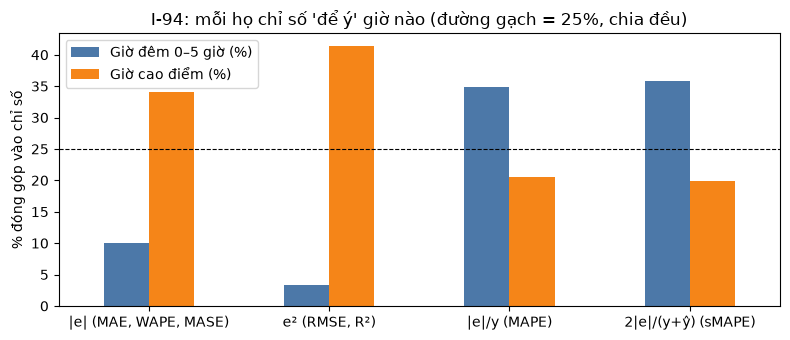

In [18]:
rows = []
for label, (frame, scale) in frames.items():
    y, p = frame["actual"].to_numpy(), frame["LightGBM"].to_numpy()
    e, hour = y - p, frame.index.hour
    night, peak = np.isin(hour, range(6)), np.isin(hour, [7, 8, 9, 16, 17, 18])
    parts = {"|e| (MAE, WAPE, MASE)": np.abs(e), "e² (RMSE, R²)": e ** 2,
             "|e|/y (MAPE)": np.where(y > 0, np.abs(e) / np.where(y > 0, y, 1), 0),
             "2|e|/(y+ŷ) (sMAPE)": 2 * np.abs(e) / (np.abs(y) + np.abs(p))}
    for name, part in parts.items():
        rows.append({"Dataset": label, "Họ chỉ số": name, "Giờ đêm 0–5 giờ (%)": part[night].sum() / part.sum() * 100,
                     "Giờ cao điểm (%)": part[peak].sum() / part.sum() * 100})
shares = pd.DataFrame(rows).set_index(["Dataset", "Họ chỉ số"])
with pd.option_context("display.precision", 1):
    display(shares)

ax = shares.loc["I-94 (cao tốc)"].plot.bar(figsize=(8, 3.5), rot=0, color=["#4C78A8", "#F58518"])
ax.axhline(25, color="black", lw=0.8, ls="--"); ax.set_ylabel("% đóng góp vào chỉ số")
ax.set_title("I-94: mỗi họ chỉ số 'để ý' giờ nào (đường gạch = 25%, chia đều)"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

**Đọc kết quả.**
- Ở I‑94 và Hồ Chí Minh, **RMSE/R² nghiêng hẳn về giờ cao điểm** (≈ 41–44% đóng góp, giờ đêm chỉ ≈ 3%), **MAPE/sMAPE lại nhìn giờ đêm** (≈ 35–36%, trong khi giờ đêm có rất ít xe). MAE/WAPE nằm giữa, gần với "mỗi chiếc xe đoán sai được đếm một lần".
- Ở Glasgow (đường phố) giờ đêm đóng góp nhiều hơn ở mọi họ (28–40%): model hệ thống sai nặng cả ban đêm, phù hợp với việc nó đoán lệch mức (bước 3.3).
- **Chọn chỉ số = chọn giờ nào quan trọng.** Với giao thông, sai ở giờ cao điểm ảnh hưởng nhiều người hơn, nên chỉ số dựa trên tổng số xe đoán sai (MAE/WAPE) hợp lý hơn chỉ số coi mọi giờ ngang nhau (MAPE).

---
## Tóm tắt bước 3.4 — bảng chấm 7 chỉ số

| Tiêu chí (đo ở đâu) | MAE | WAPE | MASE | RMSE | R² | MAPE | sMAPE |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Dễ hiểu với người ngoài (3.1) | ✓ xe/giờ | ✓✓ "sai x% lưu lượng" | ✗ cần giải thích mốc | ~ | ✗ dễ hiểu nhầm là "% đúng" | ✓ | ✗ |
| So được giữa các nơi (B) | ✗ | ✓ | ~ mẫu số tùy giai đoạn train | ✗ | ✗ phụ thuộc độ dao động của dữ liệu | ✓ | ✓ |
| Không hỏng khi có giờ 0 xe (3.1-B) | ✓ | ✓ | ✓ | ✓ | ✓ | ✗ (10¹⁷ %) | ~ (luôn 200%) |
| Model thắng vững khi đổi ngày (C) | ✓ 75–100% | ✓ | ✓ | ✓ 87–100% | ✓ | ✗ 74–93%, chọn model khác | ✗ 79–88% |
| "Để ý" giờ quan trọng (D) | ✓ theo số xe | ✓ | ✓ | giờ cao điểm | giờ cao điểm | giờ đêm | giờ đêm |
| Có mốc so sánh sẵn (3.2) | ✗ | ✗ | ✓ | ✗ | mốc quá dễ (trung bình) | ✗ | ✗ |

**Bài học về phương pháp**
1. **Tìm xem các thước đo có thật sự khác nhau không** trước khi so: 7 chỉ số ở đây chỉ là 3 họ; so 7 cột là thừa và dễ rối.
2. **Một kết luận đúng theo mọi thước đo** (cây có lag luôn đứng đầu) thì chắc chắn; **chỗ các thước đo bất đồng** là chỗ phải chọn theo mục đích.
3. **Kiểm độ vững bằng lấy mẫu lại** (bootstrap theo ngày) trước khi nói "model A tốt hơn B".
4. **Hỏi "chỉ số này để ý phần dữ liệu nào"** — giờ đêm hay giờ cao điểm — rồi đối chiếu với điều người dùng quan tâm.

**Câu hỏi cho bước 3.5:** từ bảng chấm này, chọn chỉ số cho **3 việc** — (1) chọn model khi train, (2) hiển thị cho admin ở tab Model Quality, (3) theo dõi để biết khi nào nên retrain — và viết báo cáo `E1-chi-so-danh-gia.md`.

**Tự thử:** ở ô phép thử D, đổi `"LightGBM"` thành `"XGBoost (lag)"` hoặc `"LSTM"`, chạy lại và xem phần đóng góp của giờ đêm thay đổi thế nào.

---
## Bước 3.5 — Quyết định: dùng chỉ số nào, cho việc gì

**Đang làm gì.** Áp bảng chấm của bước 3.4 vào **ba việc khác nhau** (bước 1 của khung 7 bước: *chọn để làm gì?*). Mỗi việc có người dùng và yêu cầu riêng, nên có thể cần chỉ số khác nhau.

| Việc | Ai dùng | Yêu cầu quan trọng nhất | Chỉ số chọn | Vì sao (bằng chứng) |
| --- | --- | --- | --- | --- |
| 1. **Chọn model khi train** | Hệ thống tự chọn | Xếp hạng vững, không hỏng khi có giờ 0 xe | **Giữ MAE** (trung bình kiểm tra chéo, như hiện nay); RMSE là chỉ số phụ để thấy lần sai nặng | Họ \|e\| giữ ngôi 75–99,9% khi lấy mẫu lại; MAPE từng ra 2,66·10¹⁷ trên hệ thống; R² chỉ là RMSE đội lốt |
| 2. **Hiển thị cho admin** (tab Model Quality) | Admin, GVHD, người ngoài | Dễ hiểu, so được giữa các vùng, không làm người xem tưởng nhầm | **WAPE (%)** làm số chính · MAE (xe/giờ) làm số phụ · **"so với cách đoán cùng giờ tuần trước"** · từng giờ: số xe và % sai, đánh dấu giờ ít xe | WAPE: 6,4% / 8,5% / 18,0% so được giữa 3 nơi, còn MAE 216 / 308 / 45 thì không; ở Glasgow chỉ có so với mốc mới lộ ra model kém hơn cách đoán đơn giản |
| 3. **Theo dõi để biết khi nào retrain** | Bộ phát hiện drift | Nhạy với thay đổi, ít báo nhầm, so được theo thời gian | **Họ \|e\|**: MAE hoặc WAPE theo cửa sổ trượt, so với lúc vừa train (giống quy tắc MAE +15% đang có khi chọn feature) — **kiểm ở giai đoạn 5** | Vững nhất khi lấy mẫu lại; không bị giờ đêm chi phối như MAPE |

**Không dùng làm chỉ số chính:** MAPE (hỏng khi có giờ 0 xe), sMAPE (sách FPP3 khuyên không dùng; chọn model thắng khác khi lấy mẫu lại), R² (dễ hiểu nhầm là "% đúng"; cách đoán ngây thơ cũng được ≈ 0,90 ở cao tốc).

> **Đoán trước:** với cách hiển thị mới, Glasgow sẽ trông thế nào so với I‑94?

In [19]:
CANDIDATES = ["RandomForest", "XGBoost", "LightGBM", "LSTM", "GRU"]   # 5 model hệ thống có thể chọn
rows = []
for label, (run, _) in RUNS.items():
    summary = json.loads((OUT / run / "summary.json").read_text(encoding="utf-8"))
    chosen = min(CANDIDATES, key=lambda m: summary["models"][m]["cv_MAE_mean"])   # hệ thống chọn theo CV MAE
    frame, _ = frames[label]
    y, p = frame["actual"].to_numpy(), frame[chosen].to_numpy()
    weekly = frame["Mốc: tuần trước"].to_numpy()
    mae, weekly_mae = np.mean(np.abs(y - p)), np.mean(np.abs(y - weekly))
    wape = np.abs(y - p).sum() / y.sum() * 100
    better = (1 - mae / weekly_mae) * 100
    rows.append({"Dataset": label, "Model hệ thống chọn": chosen,
                 "Hiện nay: Average difference": f"{mae:,.0f} vehicles/hour",
                 "Đề xuất: sai trung bình": f"{wape:.1f}% lưu lượng ({mae:,.0f} xe/giờ)",
                 "Đề xuất: so với cách đoán tuần trước": (f"tốt hơn {better:.0f}%" if better >= 0 else f"KÉM hơn {-better:.0f}%")})
display(pd.DataFrame(rows).set_index("Dataset"))

,Model hệ thống chọn,Hiện nay: Average difference,Đề xuất: sai trung bình,Đề xuất: so với cách đoán tuần trước
Dataset,,,,
I-94 (cao tốc),RandomForest,226 vehicles/hour,6.8% lưu lượng (226 xe/giờ),tốt hơn 30%
Glasgow GD1351_R (đường phố),LSTM,28 vehicles/hour,11.2% lưu lượng (28 xe/giờ),KÉM hơn 40%
Hồ Chí Minh (giả lập),RandomForest,307 vehicles/hour,8.5% lưu lượng (307 xe/giờ),tốt hơn 21%


**Đọc kết quả.**
- **Hiện nay** admin chỉ thấy một con số tuyệt đối (226, 28, 307 xe/giờ). Glasgow có số nhỏ nhất nên trông **tốt nhất** — đúng điều GVHD cảnh báo: *"thấy chênh lệch ít thì tưởng dự đoán đúng, nhưng thực ra chênh lệch nhiều lắm"*.
- **Với cách hiển thị đề xuất**, Glasgow lộ ra là nơi model **sai nhiều nhất theo phần trăm** và **kém hơn cả cách đoán cùng giờ tuần trước**, còn I‑94 sai khoảng 7% và tốt hơn cách đơn giản rõ rệt.
- Đây là bằng chứng cụ thể cho thay đổi ở giai đoạn 4.

### Hiển thị từng giờ ("Difference" dưới biểu đồ)

Ở I‑94, các giờ ít xe (dưới 25% lưu lượng trung bình, 17,8% số giờ) có **% sai trung vị 12,3%** so với **4,5%** ở giờ thường, nhưng chỉ góp **6,6%** tổng số xe đoán sai; số giờ sai trên 50% chỉ 1,6%. Đề xuất cho từng giờ: hiện **"sai 120 xe (12%)"**, và với giờ ít xe thêm nhãn nhỏ **"giờ ít xe"** để người xem hiểu vì sao % cao; giờ thực tế 0 xe chỉ hiện số xe (không chia cho 0).

---
## Tóm tắt giai đoạn 3

Báo cáo đầy đủ cho GVHD và để viết khóa luận: [`../E1-chi-so-danh-gia.md`](../E1-chi-so-danh-gia.md). Hình đã xuất ra [`../figures/`](../figures/).

**Bài học về phương pháp (bước 3.5)**
1. **Không có "chỉ số tốt nhất" chung chung** — chỉ có chỉ số tốt nhất **cho một việc cụ thể**. Viết rõ việc, người dùng, yêu cầu trước khi chọn.
2. **Mỗi lựa chọn kèm bằng chứng đo được và đánh đổi** (ví dụ WAPE dễ hiểu nhưng giờ đêm ít ảnh hưởng).
3. **Minh họa quyết định trên dữ liệu thật** (bảng "hiện nay / đề xuất" ở trên) giúp người khác thấy ngay vì sao nên đổi.